In [50]:

import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
SEED = 42
keras.utils.set_random_seed(SEED)
print("Keras", keras.__version__)



Keras 3.15.1


In [51]:
# Passo 2 — Dados: os mesmos dígitos da Parte 1
digitos = load_digits()
X_tr, X_te, y_tr, y_te = train_test_split(digitos.data / 16.0, digitos.target, # pixels 0–16 → 0–1
test_size=0.2, random_state=SEED, stratify=digitos.target)
print("Treino:", X_tr.shape, "| Teste:", X_te.shape)

Treino: (1437, 64) | Teste: (360, 64)


In [52]:
# Passo 3 — Montar, compilar, treinar
modelo = keras.Sequential([
keras.Input(shape=(64,)),
layers.Dense(64, activation="relu"),
layers.Dense(32, activation="relu"),
layers.Dense(10, activation="softmax"), # 10 dígitos → softmax
])
modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist = modelo.fit(X_tr, y_tr, validation_split=0.2, epochs=40, verbose=0)
print("Parâmetros:", modelo.count_params())
print(f"Acurácia no teste: {modelo.evaluate(X_te, y_te, verbose=0)[1]:.1%}")

Parâmetros: 6570
Acurácia no teste: 95.8%


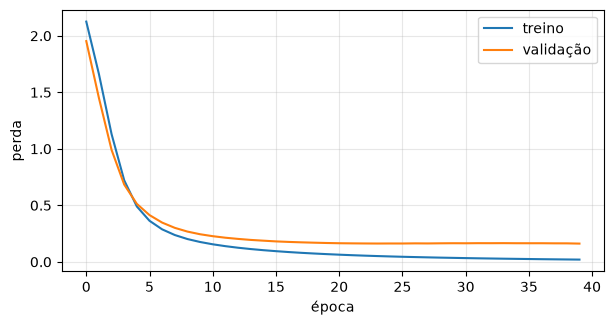

In [53]:
# Passo 4 — Curvas de aprendizado
plt.figure(figsize=(7, 3.4))
plt.plot(hist.history["loss"], label="treino")
plt.plot(hist.history["val_loss"], label="validação")
plt.xlabel("época"); plt.ylabel("perda"); plt.legend(); plt.grid(alpha=0.3); plt.show()

In [54]:
def criar_rede(dropout):
    m = keras.Sequential([
        keras.Input(shape=(64,)),
        layers.Dense(256, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(256, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(10, activation="softmax")
    ])

    m.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return m

In [55]:
X_pouco, y_pouco = X_tr[:200], y_tr[:200].copy()

X_val, y_val = X_tr[200:600], y_tr[200:600]

rng = np.random.default_rng(SEED)

y_pouco[rng.choice(200, 40, replace=False)] = rng.integers(0, 10, 40)

def criar_rede(dropout):
    m = keras.Sequential([
        keras.Input(shape=(64,)),
        layers.Dense(256, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(256, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(10, activation="softmax")
    ])

    m.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return m

keras.utils.set_random_seed(SEED)

decoreba = criar_rede(0.0)

h_dec = decoreba.fit(
    X_pouco,
    y_pouco,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=16,
    verbose=0
)

keras.utils.set_random_seed(SEED)

disciplinada = criar_rede(0.5)

parada = keras.callbacks.EarlyStopping(
    patience=10,
    restore_best_weights=True
)

h_dis = disciplinada.fit(
    X_pouco,
    y_pouco,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=16,
    verbose=0,
    callbacks=[parada]
)

for nome, h, m in [
    ("Decoreba", h_dec, decoreba),
    ("Disciplinada", h_dis, disciplinada)
]:
    print(
        f"{nome:12s} treino: {h.history['accuracy'][-1]:.1%} | "
        f"teste: {m.evaluate(X_te, y_te, verbose=0)[1]:.1%}"
    )

Decoreba     treino: 100.0% | teste: 76.4%
Disciplinada treino: 84.0% | teste: 88.1%


In [56]:
def gerar_entregas(n=3000, seed=2026):
    rng = np.random.default_rng(seed)

    dist = rng.uniform(0.3, 12, n)
    hora = rng.integers(0, 24, n)

    chuva = rng.binomial(1, 0.25, n)
    fila = rng.poisson(4, n)
    prato = rng.integers(1, 4, n)

    pico = (
        np.exp(-((hora - 12.5) ** 2) / 3)
        + np.exp(-((hora - 20) ** 2) / 3)
    )

    minutos = (
        12
        + 3.2 * dist
        + 14 * pico * (1 + 0.5 * chuva)
        + 1.8 * fila
        + 4 * prato
        + 6 * chuva
        + 0.9 * chuva * dist
        + rng.normal(0, 3, n)
    )

    return pd.DataFrame({
        "distancia_km": dist.round(1),
        "hora": hora,
        "chovendo": chuva,
        "pedidos_na_fila": fila,
        "complexidade_prato": prato,
        "minutos": minutos.round(1)
    })

entregas = gerar_entregas()

os.makedirs("dados", exist_ok=True)
entregas.to_csv(
    "dados/entregas.csv",
    index=False
)

print("Arquivo existe?", os.path.exists("dados/entregas.csv"))
print("Conteúdo da pasta:", os.listdir("dados"))


Arquivo existe? True
Conteúdo da pasta: ['entregas.csv']


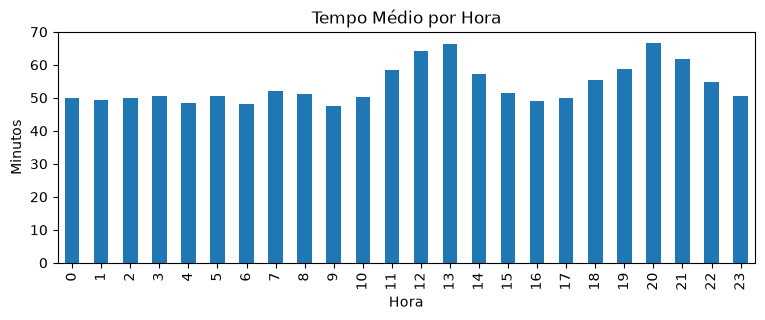

In [57]:
entregas.groupby("hora")["minutos"].mean().plot(
    kind="bar",
    figsize=(9, 3),
    title="Tempo Médio por Hora"
)

os.makedirs("imagens", exist_ok=True)

plt.xlabel("Hora")
plt.ylabel("Minutos")

plt.savefig(
    "imagens/grafico_horarios.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [58]:
# Passo 8 — Treino / validação / teste e o baseline linear
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error
FEATURES = ["distancia_km", "hora", "chovendo", "pedidos_na_fila", "complexidade_prato"]
X_resto, X_teste, y_resto, y_teste = train_test_split(entregas[FEATURES], entregas["minutos"],
test_size=0.2, random_state=SEED)
X_treino, X_valid, y_treino, y_valid = train_test_split(X_resto, y_resto, test_size=0.25, random_state=SEED)
linear = make_pipeline(StandardScaler(), LinearRegression()).fit(X_treino, y_treino)
print(f"Baseline linear → erro médio na validação: {mean_absolute_error(y_valid, linear.predict(X_valid)):.1f} min")


Baseline linear → erro médio na validação: 4.6 min


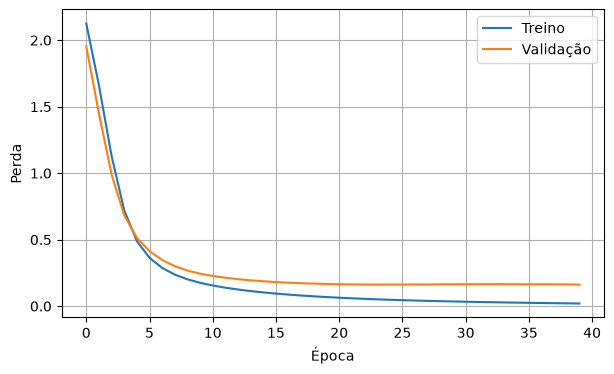

In [59]:
plt.figure(figsize=(7, 4))

plt.plot(hist.history["loss"], label="Treino")
plt.plot(hist.history["val_loss"], label="Validação")

plt.xlabel("Época")
plt.ylabel("Perda")

plt.legend()
plt.grid(True)

plt.savefig(
    "imagens/curva_treinamento.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [60]:
# Passo 9 — Testar arquiteturas e registrar
registros, redes = [], {}
for camadas in [(8,), (32,), (64, 32)]:
    rede = make_pipeline(StandardScaler(),
    MLPRegressor(hidden_layer_sizes=camadas, solver="lbfgs", max_iter=3000, random_state=SEED))
    rede.fit(X_treino, y_treino)
    redes[str(camadas)] = camadas
    registros.append({"camadas": str(camadas),
    "erro_validacao_min": round(mean_absolute_error(y_valid, rede.predict(X_valid)), 2)})
    experimentos = pd.DataFrame(registros)
    experimentos.to_csv("experimentos.csv", index=False)
    print(experimentos.to_string(index=False))

camadas  erro_validacao_min
   (8,)                4.03
camadas  erro_validacao_min
   (8,)                4.03
  (32,)                2.58
 camadas  erro_validacao_min
    (8,)                4.03
   (32,)                2.58
(64, 32)                3.14


c:\Users\ladei\OneDrive\Marcus\Documentos\att\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


In [61]:
# Passo 10 — Abrir o cofre do teste (uma vez só!)
melhor = redes[experimentos.sort_values("erro_validacao_min").iloc[0]["camadas"]]
modelo_entregas = make_pipeline(StandardScaler(),
MLPRegressor(hidden_layer_sizes=melhor, solver="lbfgs", max_iter=3000, random_state=SEED))
modelo_entregas.fit(X_resto, y_resto)
linear.fit(X_resto, y_resto)
erro_linear = mean_absolute_error(y_teste, linear.predict(X_teste))
erro_rede = mean_absolute_error(y_teste, modelo_entregas.predict(X_teste))
print(f"Melhor arquitetura: {melhor}")
print(f"TESTE → linear erra {erro_linear:.1f} min | rede erra {erro_rede:.1f} min")
print(f"A rede erra {1 - erro_rede / erro_linear:.0%} menos que o baseline.")


Melhor arquitetura: (32,)
TESTE → linear erra 4.5 min | rede erra 2.5 min
A rede erra 45% menos que o baseline.


In [62]:
# Passo 11 — Salvar e carregar o modelo
import joblib
joblib.dump(modelo_entregas, "modelo_entregas.joblib")
carregado = joblib.load("modelo_entregas.joblib")
print("Arquivo salvo:", os.path.getsize("modelo_entregas.joblib") // 1024, "KB")
print("Mesmas previsões?", np.allclose(carregado.predict(X_teste[:5]), modelo_entregas.predict(X_teste[:5])))

Arquivo salvo: 11 KB
Mesmas previsões? True


In [63]:
# Passo 12 — Função de previsão + painel interativo
from ipywidgets import interact
def estimar_entrega(distancia_km=4.0, hora=20, chovendo=False, pedidos_na_fila=4, complexidade_prato=2):
    entrada = pd.DataFrame([[distancia_km, hora, int(chovendo), pedidos_na_fila, complexidade_prato]],
    columns=FEATURES)
    minutos = round(float(carregado.predict(entrada)[0]))
    print(f" Seu pedido chega em ~{minutos} min")
    return minutos
estimar_entrega(8, 12, True, 6, 3)
estimar_entrega(2, 15, False, 1, 1)
interact(estimar_entrega, distancia_km=(0.3, 12, 0.1), hora=(0, 23),
pedidos_na_fila=(0, 15), complexidade_prato=[1, 2, 3]);

 Seu pedido chega em ~93 min
 Seu pedido chega em ~27 min


interactive(children=(FloatSlider(value=4.0, description='distancia_km', max=12.0, min=0.3), IntSlider(value=2…

In [64]:
# Passo 13 — Model card
card = f'''# Model Card — Tempo de Entrega RangoJá
- **Uso pretendido:** mostrar ao cliente a previsão de chegada do pedido.
- **Não usar para:** punir ou remunerar entregadores.
- **Dados:** {len(entregas)} entregas sintéticas (seed 2026).
- **Modelo:** rede neural {melhor}, comparada a uma regressão linear.
- **Desempenho no teste:** erra em média {erro_rede:.1f} min (baseline: {erro_linear:.1f} min).
- **Limitações:** não conhece trânsito real nem acidentes; re-treinar com dados reais.
'''
open("MODEL_CARD.md", "w", encoding="utf-8").write(card)
print(card)

# Model Card — Tempo de Entrega RangoJá
- **Uso pretendido:** mostrar ao cliente a previsão de chegada do pedido.
- **Não usar para:** punir ou remunerar entregadores.
- **Dados:** 3000 entregas sintéticas (seed 2026).
- **Modelo:** rede neural (32,), comparada a uma regressão linear.
- **Desempenho no teste:** erra em média 2.5 min (baseline: 4.5 min).
- **Limitações:** não conhece trânsito real nem acidentes; re-treinar com dados reais.

